
# Exercice 2 — Risque de Bayes pour la perte absolue

## Question 0 (M) 

On veut une fonction $f:\mathbb{R}\to\mathbb{R}$ dont la dérivée s'annule en un point qui n'est pas un extremum. Le cas d'école, c'est $$f(x) = x^{3}, \qquad x_0 = 0.$$ On a $f'(x) = 3x^2$ donc $f'(0)=0$, mais $f$ est strictement croissante
($a^3 < 0 < b^3$ dès que $a<0<b$), donc $0$ n'est ni un minimum ni un maximum local.

L'intérêt de cette petite question, c'est de garder en tête qu'une dérivée nulle ne garantit pas un minimum. On retombe exactement là-dessus à la question 2, et c'est la convexité qui permettra de conclure proprement.



## Question 1 (M + C)

Pour la perte quadratique, on vient de voir que le prédicteur de Bayes est l'espérance conditionnelle. On cherche maintenant un cadre où le prédicteur pour la perte absolue s'en éloigne visiblement.

Le cadre : $X \sim \mathcal{U}([0,1])$, et sachant $X=x$, $Y$ suit une loi exponentielle de moyenne $m(x) = 1+x$ :
$$p_{Y\mid X=x}(y) = \frac{1}{m(x)}\,e^{-y/m(x)}, \qquad y \ge 0.$$
J'ai choisi l'exponentielle parce qu'elle est bien asymétrique : sa moyenne et sa médiane ne coïncident pas, et c'est justement cet écart qui va distinguer les deux prédicteurs.

Pour une exponentielle de moyenne $m$, l'espérance vaut $m$ et la médiane se trouve en résolvant $1 - e^{-z/m} = \tfrac12$, soit $z = m\ln 2$. Nos deux candidats sont donc la moyenne conditionnelle $m(x) = 1+x$ et la médiane conditionnelle $g(x) = (1+x)\ln 2$.

Le risque absolu, à $x$ fixé : Posons $h(z) = \mathbb{E}[\,|Y-z|\mid X=x\,]$ avec $m = m(x)$. On coupe l'intégrale en $y \le z$ et $y > z$ :
$$h(z) = \int_{0}^{z}(z-y)\tfrac{1}{m}e^{-y/m}\,dy
       + \int_{z}^{+\infty}(y-z)\tfrac{1}{m}e^{-y/m}\,dy.$$
En intégrant par parties ($\int_0^z y\,\tfrac1m e^{-y/m}\,dy = m - (z+m)e^{-z/m}$), les deux morceaux se recombinent en une expression très simple, valable pour $z \ge 0$ (la coupure de l'intégrale en $0$ et $z$ le suppose, et nos deux candidats sont bien positifs) :
$$h(z) = z - m + 2m\,e^{-z/m}, \qquad z \ge 0.$$
La cellule de code ci-dessous recoupe cette formule fermée avec une intégration numérique directe, les deux donnent la même chose. On l'évalue sur nos deux candidats :
$$h(m) = \frac{2m}{e}, \qquad
h(m\ln 2) = m\ln 2 - m + 2m\cdot\tfrac12 = m\ln 2.$$

Le risque réel : Il reste à moyenner sur $X$, avec $\mathbb{E}[m(X)] = \int_0^1(1+x)\,dx = \tfrac32$ :
$$R_{\text{abs}}(\text{moyenne}) = \frac{2}{e}\cdot\frac32 = \frac{3}{e}
\approx 1.1036, \qquad
R_{\text{abs}}(\text{médiane}) = \frac32\ln 2 \approx 1.0397.$$
La médiane conditionnelle fait donc strictement mieux que la moyenne pour la perte absolue : c'est bien un cas où les deux prédicteurs de Bayes diffèrent. La question 2 montrera que cette médiane est exactement le prédicteur optimal.

Par symétrie, regardons ce que ça donne sous la perte quadratique. Prédire une constante $c$ sachant $X=x$ coûte $\operatorname{Var}(Y\mid x) + (m-c)^2 = m^2 + (m-c)^2$ (la variance d'une exponentielle de moyenne $m$ vaut $m^2$). Avec $\mathbb{E}[m(X)^2] = \int_0^1(1+x)^2\,dx = \tfrac73$ :
$$R_{\text{quad}}(\text{moyenne}) = \frac73 \approx 2.3333, \qquad
R_{\text{quad}}(\text{médiane}) = \frac73\big(1+(1-\ln 2)^2\big) \approx 2.5530.$$
Cette fois c'est la moyenne qui gagne, ce qui est rassurant : chaque prédicteur est le meilleur pour sa propre perte. La simulation qui suit retrouve ces quatre valeurs.


In [ ]:
# vérification numérique de la forme close h(z) = z - m + 2m e^(-z/m), z >= 0
import numpy as np
from scipy.integrate import quad

for m in (1.0, 1.5, 2.0):
    for z in (m, m * np.log(2)):
        integrale, _ = quad(lambda y: abs(y - z) * np.exp(-y / m) / m, 0, np.inf)
        forme_close = z - m + 2 * m * np.exp(-z / m)
        print(f"m={m:.1f} z={z:.4f} : intégrale={integrale:.6f}  "
              f"forme close={forme_close:.6f}  écart={abs(integrale - forme_close):.2e}")

m=1.0 z=1.0000 : intégrale=0.735759  forme close=0.735759  écart=2.22e-16
m=1.0 z=0.6931 : intégrale=0.693147  forme close=0.693147  écart=1.23e-10
m=1.5 z=1.5000 : intégrale=1.103638  forme close=1.103638  écart=1.59e-11
m=1.5 z=1.0397 : intégrale=1.039721  forme close=1.039721  écart=4.64e-10
m=2.0 z=2.0000 : intégrale=1.471518  forme close=1.471518  écart=3.58e-12
m=2.0 z=1.3863 : intégrale=1.386294  forme close=1.386294  écart=7.05e-12


In [ ]:
# Cadre : X ~ Uniforme([0, 1]), et Y | X = x ~ Exponentielle de moyenne 1 + x. On compare moyenne et médiane conditionnelles,
# sous les deux pertes, sur un grand jeu de test, et on confronte les risques empiriques aux valeurs théoriques.

import matplotlib.pyplot as plt
import numpy as np

N_TEST = int(1e7)


def conditional_mean(x: np.ndarray) -> np.ndarray:
    """
    Moyenne conditionnelle E[Y | X = x] = 1 + x.
    C'est le prédicteur de Bayes pour la perte quadratique.

    Paramètres :
        x (np.ndarray) : valeurs d'entrée dans [0, 1].

    Retour :
        np.ndarray : moyenne conditionnelle de Y sachant x.
    """
    return 1 + x


def conditional_median(x: np.ndarray) -> np.ndarray:
    """
    Médiane conditionnelle (1 + x) * ln(2).
    C'est le prédicteur de Bayes pour la perte absolue (cf. question 2).

    Paramètres :
        x (np.ndarray) : valeurs d'entrée dans [0, 1].

    Retour :
        np.ndarray : médiane conditionnelle de Y sachant x.
    """
    return (1 + x) * np.log(2)


rng = np.random.default_rng(seed=0)

# jeu de test : on tire X, puis Y | X selon la loi exponentielle correspondante
x_test = rng.uniform(low=0, high=1, size=N_TEST)
y_test = rng.exponential(scale=conditional_mean(x_test))

predictions = {
    "f*_quadratique (moyenne cond.)": conditional_mean(x_test),
    "f*_absolue (médiane cond.)": conditional_median(x_test),
}

print("risques empiriques de test (n_test = 1e7) :\n")
for name, y_pred in predictions.items():
    risk_abs = np.mean(np.abs(y_test - y_pred))
    risk_sq = np.mean((y_test - y_pred) ** 2)
    print(f"{name}")
    print(f"    perte absolue     : {risk_abs:.4f}")
    print(f"    perte quadratique : {risk_sq:.4f}\n")

print("risques théoriques (calculés plus haut) :")
print(f"    perte absolue, moyenne : (3/e)      = {3 / np.e:.4f}")
print(f"    perte absolue, médiane : (3/2)ln(2) = {1.5 * np.log(2):.4f}")
print(f"    perte quadr.,  moyenne : 7/3        = {7 / 3:.4f}")
print(
    "    perte quadr.,  médiane : (7/3)(1 + (1-ln2)^2) "
    f"= {7 / 3 * (1 + (1 - np.log(2)) ** 2):.4f}"
)

risques empiriques de test (n_test = 1e7) :

f*_quadratique (moyenne cond.)
    perte absolue     : 1.1032
    perte quadratique : 2.3291

f*_absolue (médiane cond.)
    perte absolue     : 1.0394
    perte quadratique : 2.5483

risques théoriques (calculés plus haut) :
    perte absolue, moyenne : (3/e)      = 1.1036
    perte absolue, médiane : (3/2)ln(2) = 1.0397
    perte quadr.,  moyenne : 7/3        = 2.3333
    perte quadr.,  médiane : (7/3)(1 + (1-ln2)^2) = 2.5530


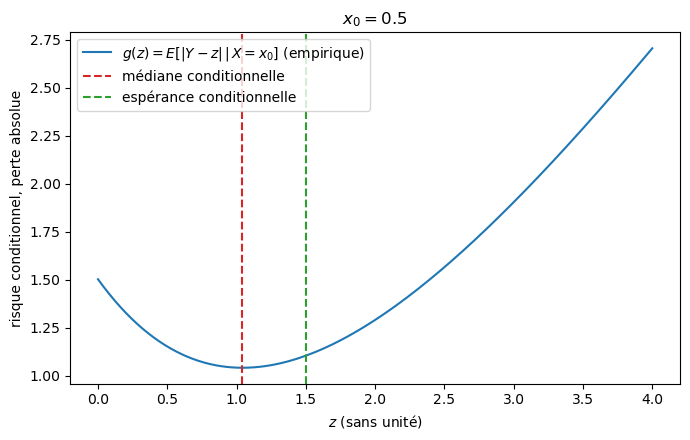

In [ ]:
# à x0 fixé, on trace le risque conditionnel z -> E[|Y - z| | X = x0] pour voir que son minimum tombe sur la médiane conditionnelle, pas sur la moyenne
x0 = 0.5
y_cond = rng.exponential(scale=1 + x0, size=int(1e6))
z_values = np.linspace(0, 4, 200)
g_values = [np.mean(np.abs(y_cond - z)) for z in z_values]

plt.figure(figsize=(7, 4.5))
plt.plot(z_values, g_values, label=r"$g(z)=E[|Y-z|\,|\,X=x_0]$ (empirique)")
plt.axvline(
    (1 + x0) * np.log(2),
    color="tab:red",
    linestyle="--",
    label="médiane conditionnelle",
)
plt.axvline(
    1 + x0, color="tab:green", linestyle="--", label="espérance conditionnelle"
)
plt.xlabel("$z$ (sans unité)")
plt.ylabel("risque conditionnel, perte absolue")
plt.title(f"$x_0={x0}$")
plt.legend()
plt.tight_layout()
plt.show()


### Résultats :

| prédicteur | perte absolue (test) | théorie | perte quadratique (test) | théorie |
|---|---|---|---|---|
| moyenne cond. | 1.1032 | $3/e \approx 1.1036$ | 2.3291 | $7/3 \approx 2.3333$ |
| médiane cond. | 1.0394 | $\tfrac32\ln 2 \approx 1.0397$ | 2.5483 | $\approx 2.5530$ |

Les quatre valeurs simulées tombent sur la théorie. C'est très précis sur les pertes absolues. C'est un peu moins net sur les pertes quadratiques, mais c'est normal, le carré d'une exponentielle a une grosse variance et converge plus lentement en Monte-Carlo. Le graphe du risque conditionnel $z \mapsto \mathbb{E}[|Y-z|\mid X=x_0]$ pour $x_0 = 0.5$ montre bien que le minimum est sur la médiane, pas sur la moyenne.

## Question 2 (M) : le prédicteur de Bayes pour la perte absolue

On se place dans le cadre général de l'énoncé. Pour $x$ fixé, la loi de $Y\mid X=x$ a une densité continue $p := p_{Y\mid X=x}$ et un moment d'ordre 1. On note $F$ sa fonction de répartition et on cherche à minimiser
$$g(z) = \int_{\mathbb{R}} |y-z|\,p(y)\,dy.$$

Comme $|y-z| \le |y| + |z|$, on a $g(z) \le \mathbb{E}[|Y|\mid X=x] + |z| < \infty$ grâce au moment d'ordre 1 : $g(z)$ est donc finie pour tout $z$.

Proposition : Le minimiseur $f^{*}_{\text{abs}}(x)$ est une médiane de $Y\mid X=x$, c'est-à-dire un $z$ tel que $F(z) = \tfrac12$.

Étape 1 : $g$ est convexe. Chaque fonction $z\mapsto |y-z|$ est convexe, et une moyenne (ici une intégrale à poids positifs $p(y)\,dy$) de fonctions convexes reste convexe. Concrètement, pour $t\in[0,1]$,
$$g(tz_1+(1-t)z_2) \le \int \big(t|y-z_1| + (1-t)|y-z_2|\big)p(y)\,dy
= t\,g(z_1)+(1-t)\,g(z_2).$$
C'est ce qui nous protège du piège de la question 0 : sur une fonction convexe, un point à dérivée nulle est forcément un minimum global.

Étape 2 : calcul de $g'$. On sépare selon le signe de $y-z$, puis on regroupe :
$$
\begin{aligned}
g(z) &= \int_{-\infty}^{z}(z-y)\,p(y)\,dy + \int_{z}^{+\infty}(y-z)\,p(y)\,dy\\
&= z\,F(z) - \int_{-\infty}^{z} y\,p(y)\,dy + \int_{z}^{+\infty} y\,p(y)\,dy
   - z\big(1-F(z)\big)\\
&= z\big(2F(z)-1\big) - \int_{-\infty}^{z} y\,p(y)\,dy + \int_{z}^{+\infty} y\,p(y)\,dy.
\end{aligned}
$$
Les deux intégrales restantes convergent (moment d'ordre 1), et comme $p$ est continue, $y \mapsto y\,p(y)$ l'est aussi. Le théorème fondamental de l'analyse donne alors leurs dérivées, $z\,p(z)$ et $-z\,p(z)$, et on sait que $F' = p$. En dérivant :
$$g'(z) = \big(2F(z)-1\big) + 2z\,p(z) - z\,p(z) - z\,p(z) = 2F(z) - 1.$$
Les termes en $z\,p(z)$ se compensent, et il ne reste que $g'(z) = 2F(z)-1$.

Étape 3 : conclusion. $F$ est continue, avec $\lim_{z\to-\infty}F(z) = 0$ et $\lim_{z\to+\infty}F(z) = 1$. Il existe donc des points $a < b$ avec $F(a) < \tfrac12 < F(b)$, et le théorème des valeurs intermédiaires sur $[a,b]$ fournit un $z_{\text{med}}$ avec $F(z_{\text{med}}) = \tfrac12$, où $g'(z_{\text{med}}) = 0$. La convexité de l'étape 1 assure que ce point critique est un minimum global :
$$f^{*}_{\text{abs}}(x) = z_{\text{med}}, \qquad F(z_{\text{med}}) = \tfrac12,$$
soit la médiane conditionnelle. Si $p > 0$ partout, $F$ est strictement croissante et cette médiane est unique. Si $F$ reste bloquée à $\tfrac12$ sur tout un intervalle, alors tout l'intervalle minimise $g$ et le prédicteur est défini à cet ensemble de médianes près.

Et on retombe bien sur la question 1 : dans le cas exponentiel la médiane conditionnelle valait $m(x)\ln 2$, ce qui est cohérent avec ce résultat général.


## Conclusion :

Bilan des trois questions : la question 0 rappelle qu'un point à dérivée nulle n'est pas forcément un minimum, ce qui nous a servi de garde-fou. La question 1 exhibe un cadre concret (loi exponentielle) où le prédicteur de Bayes pour la perte absolue, la médiane conditionnelle, diffère de celui de la perte quadratique, l'espérance conditionnelle, et la simulation le confirme numériquement. La question 2 généralise : pour toute loi conditionnelle à densité continue et moment d'ordre 1, le prédicteur de Bayes pour la perte absolue est la médiane conditionnelle. Autrement dit, changer de fonction de perte change la cible optimale, un point qui compte en pratique dès que les données sont asymétriques.